In [8]:
!pip install -q openai-whisper
!pip install -q language-tool-python
!pip install -q transformers sentence-transformers
!pip install -q catboost

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 15.8 MB/s eta 0:00:0000:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.2/63.2 kB 2.3 MB/s eta 0:00:00


In [9]:
import os
import re
import gc
import json
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import librosa
import librosa.display
import soundfile as sf

import torch

from tqdm.auto import tqdm

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.ensemble import GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_squared_error

from scipy.stats import pearsonr

from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)
print("Torch:", torch.__version__)

Device: cuda
Torch: 2.11.0+cu128


In [10]:
BASE_DIR = Path(
    "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final"
)

TRAIN_DIR = BASE_DIR / "train"
TEST_DIR = BASE_DIR / "test"

TRAIN_CSV = BASE_DIR / "train.csv"
TEST_CSV = BASE_DIR / "test.csv"

print("Train directory:", TRAIN_DIR)
print("Test directory :", TEST_DIR)

print("Train CSV exists:", TRAIN_CSV.exists())
print("Test CSV exists :", TEST_CSV.exists())

print("Train audio files:", len(list(TRAIN_DIR.glob("*.wav"))))
print("Test audio files :", len(list(TEST_DIR.glob("*.wav"))))

Train directory: /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train
Test directory : /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test
Train CSV exists: True
Test CSV exists : True
Train audio files: 769
Test audio files : 216


In [11]:
train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)

display(train_df.head())
display(test_df.head())

Train shape: (769, 2)
Test shape : (216, 2)


,filename,label
0,audio_192.wav,3.0
1,audio_436.wav,3.0
2,audio_447.wav,3.5
3,audio_126.wav,2.0
4,audio_61.wav,2.0


,filename,label
0,audio_128.wav,-1
1,audio_156.wav,-1
2,audio_19.wav,-1
3,audio_108.wav,-1
4,audio_206.wav,-1


In [12]:
print("Train columns:", train_df.columns.tolist())
print("Test columns :", test_df.columns.tolist())

Train columns: ['filename', 'label']
Test columns : ['filename', 'label']


In [13]:
FILENAME_COL = "filename"

TARGET_COL = "label"

print(train_df[FILENAME_COL].head())
print(train_df[TARGET_COL].describe())

0    audio_192.wav
1    audio_436.wav
2    audio_447.wav
3    audio_126.wav
4     audio_61.wav
Name: filename, dtype: object
count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64


In [14]:
train_audio_map = {
    p.name: str(p)
    for p in TRAIN_DIR.glob("*.wav")
}

test_audio_map = {
    p.name: str(p)
    for p in TEST_DIR.glob("*.wav")
}

print("Mapped train:", len(train_audio_map))
print("Mapped test :", len(test_audio_map))

Mapped train: 769
Mapped test : 216


In [15]:
missing_train = [
    f for f in train_df[FILENAME_COL]
    if f not in train_audio_map
]

missing_test = [
    f for f in test_df[FILENAME_COL]
    if f not in test_audio_map
]

print("Missing train:", len(missing_train))
print("Missing test :", len(missing_test))

if missing_train:
    print(missing_train[:10])

if missing_test:
    print(missing_test[:10])

Missing train: 0
Missing test : 0


In [16]:
y = train_df[TARGET_COL].astype(float).values

print("Target distribution:")
print(pd.Series(y).value_counts().sort_index())

Target distribution:
0.0     37
1.0      1
1.5      3
2.0    102
2.5     79
3.0    174
3.5     64
4.0    124
4.5     52
5.0    133
Name: count, dtype: int64


In [18]:
def calculate_rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))


def calculate_pearson(y_true, y_pred):
    return pearsonr(y_true, y_pred)[0]


def evaluate_model(name, y_true, y_pred):
    y_pred = np.clip(y_pred, 0, 5)

    rmse = calculate_rmse(y_true, y_pred)
    pearson = calculate_pearson(y_true, y_pred)

    print(f"\n{name}")
    print("-" * 40)
    print("RMSE   :", rmse)
    print("Pearson:", pearson)

    return rmse, pearson

In [19]:
import whisper

WHISPER_MODEL = "small.en"

print("Loading Whisper:", WHISPER_MODEL)

asr = whisper.load_model(
    WHISPER_MODEL,
    device=DEVICE
)

print("Whisper loaded.")

Loading Whisper: small.en


100%|████████████████████████████████████████| 461M/461M [00:01<00:00, 248MiB/s]


Whisper loaded.


In [20]:
CACHE_DIR = Path("/kaggle/working/grammar_cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)

TRANSCRIPT_TRAIN = CACHE_DIR / "transcripts_train.json"
TRANSCRIPT_TEST = CACHE_DIR / "transcripts_test.json"

print(CACHE_DIR)

/kaggle/working/grammar_cache


In [22]:
WHISPER_PROMPT = (
    "This is a spoken English response from a candidate. "
    "Transcribe the exact spoken English carefully."
)


def transcribe_audio(path):

    result = asr.transcribe(
        path,
        language="en",
        task="transcribe",
        word_timestamps=True,
        initial_prompt=WHISPER_PROMPT,
        condition_on_previous_text=False,
        temperature=0,
        fp16=(DEVICE == "cuda")
    )

    segments = result.get("segments", [])

    text = result.get("text", "").strip()

    words = []

    for seg in segments:
        for w in seg.get("words", []):
            words.append({
                "word": w.get("word", "").strip(),
                "start": w.get("start", None),
                "end": w.get("end", None),
                "probability": w.get("probability", None)
            })

    return {
        "text": text,
        "segments": segments,
        "words": words
    }

In [24]:
if TRANSCRIPT_TRAIN.exists():

    with open(TRANSCRIPT_TRAIN, "r", encoding="utf-8") as f:
        transcripts_train = json.load(f)

    print("Loaded cached train transcripts.")

else:

    transcripts_train = {}

    for filename in tqdm(
        train_df[FILENAME_COL],
        desc="Transcribing train"
    ):

        path = train_audio_map[filename]

        transcripts_train[filename] = transcribe_audio(path)

    with open(
        TRANSCRIPT_TRAIN,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(
            transcripts_train,
            f,
            ensure_ascii=False
        )

print("Train transcripts:", len(transcripts_train))

Transcribing train:   0%|          | 0/769 [00:00<?, ?it/s]

Train transcripts: 769


In [25]:
if TRANSCRIPT_TEST.exists():

    with open(TRANSCRIPT_TEST, "r", encoding="utf-8") as f:
        transcripts_test = json.load(f)

    print("Loaded cached test transcripts.")

else:

    transcripts_test = {}

    for filename in tqdm(
        test_df[FILENAME_COL],
        desc="Transcribing test"
    ):

        path = test_audio_map[filename]

        transcripts_test[filename] = transcribe_audio(path)

    with open(
        TRANSCRIPT_TEST,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(
            transcripts_test,
            f,
            ensure_ascii=False
        )

print("Test transcripts:", len(transcripts_test))

Transcribing test:   0%|          | 0/216 [00:00<?, ?it/s]

Test transcripts: 216


In [26]:
for filename in list(transcripts_train.keys())[:5]:

    print("=" * 80)
    print(filename)
    print(transcripts_train[filename]["text"])

audio_192.wav
Well, the playground is very, very beautiful and fun. There are, there are playthings like the merry-go-round, the swing. The students usually enjoy the swing. It has to be like, It's more like a game of play, because one sits on it and the other is not. We'll have to finish. And the mayor goes around, which is fine for me. And most of them play for the fall. On some parks, while others just eat the swing, some of the kids like to build sand crushes. And most times you hear the sound of screaming children laughing kids.
audio_436.wav
The scene of a school playground, our playground looks like a very big playground having a more and more greenery trees in which way students like to garden a more trees to have a fresh air and all having a fresh oxygen. These in the playground, these trees gives a very greenery view which will be very pleasant to our minds and will give relaxation. Where students like to play activities of games like Coco, Volleyballs and Running Race, we li

In [27]:
FILLERS = {
    "um",
    "uh",
    "umm",
    "er",
    "erm",
    "hmm",
    "like",
    "you know"
}

SUBORDINATE_WORDS = {
    "because",
    "although",
    "though",
    "while",
    "when",
    "if",
    "unless",
    "since",
    "that",
    "which",
    "who",
    "where",
    "after",
    "before",
    "until"
}

def tokenize_text(text):

    return re.findall(
        r"\b[a-zA-Z]+(?:'[a-zA-Z]+)?\b",
        text.lower()
    )

In [28]:
def extract_hand_features(record):

    text = record["text"]

    words = tokenize_text(text)

    n_words = len(words)

    unique_words = len(set(words))

    if n_words == 0:
        return {
            "n_words": 0,
            "unique_words": 0,
            "ttr": 0,
            "mean_word_len": 0,
            "long_word_fraction": 0,
            "filler_rate": 0,
            "repeat_rate": 0,
            "subordinate_rate": 0,
            "sentence_count": 0,
            "mean_sentence_length": 0,
            "max_sentence_length": 0,
            "std_sentence_length": 0,
            "wpm": 0,
            "duration": 0,
            "speech_ratio": 0,
            "lead_silence": 0,
            "trail_silence": 0,
            "pause_count": 0,
            "long_pause_count": 0,
            "pause_rate": 0,
            "mean_gap": 0,
            "max_gap": 0,
            "asr_conf_mean": 0,
            "asr_conf_low": 0
        }

    # --------------------------------
    # Duration
    # --------------------------------

    segments = record.get("segments", [])

    if segments:

        duration = max(
            float(seg.get("end", 0) or 0)
            for seg in segments
        )

    else:
        duration = 0

    # --------------------------------
    # WPM
    # --------------------------------

    minutes = max(duration / 60, 1e-6)

    wpm = n_words / minutes

    # --------------------------------
    # Lexical
    # --------------------------------

    word_lengths = [len(w) for w in words]

    mean_word_len = np.mean(word_lengths)

    long_word_fraction = np.mean(
        [l >= 7 for l in word_lengths]
    )

    ttr = unique_words / max(n_words, 1)

    # --------------------------------
    # Fillers
    # --------------------------------

    filler_count = sum(
        1 for w in words
        if w in FILLERS
    )

    filler_rate = filler_count / max(n_words, 1)

    # --------------------------------
    # Repetition
    # --------------------------------

    repeat_count = sum(
        words[i] == words[i - 1]
        for i in range(1, n_words)
    )

    repeat_rate = repeat_count / max(n_words - 1, 1)

    # --------------------------------
    # Subordinate structures
    # --------------------------------

    subordinate_count = sum(
        1 for w in words
        if w in SUBORDINATE_WORDS
    )

    subordinate_rate = (
        subordinate_count / max(n_words, 1)
    )

    # --------------------------------
    # Sentence structure
    # --------------------------------

    sentences = [
        s.strip()
        for s in re.split(
            r"[.!?]+",
            text
        )
        if s.strip()
    ]

    sentence_lengths = [
        len(tokenize_text(s))
        for s in sentences
    ]

    sentence_count = len(sentence_lengths)

    if sentence_count:

        mean_sentence_length = np.mean(
            sentence_lengths
        )

        max_sentence_length = np.max(
            sentence_lengths
        )

        std_sentence_length = np.std(
            sentence_lengths
        )

    else:

        mean_sentence_length = 0
        max_sentence_length = 0
        std_sentence_length = 0

    # --------------------------------
    # Word timestamps
    # --------------------------------

    timed_words = [
        w for w in record.get("words", [])
        if w.get("start") is not None
        and w.get("end") is not None
    ]

    gaps = []

    for i in range(1, len(timed_words)):

        previous_end = float(
            timed_words[i - 1]["end"]
        )

        current_start = float(
            timed_words[i]["start"]
        )

        gap = current_start - previous_end

        if gap >= 0:
            gaps.append(gap)

    if gaps:

        pause_count = sum(
            g > 0.5 for g in gaps
        )

        long_pause_count = sum(
            g > 1.0 for g in gaps
        )

        mean_gap = np.mean(gaps)

        max_gap = np.max(gaps)

    else:

        pause_count = 0
        long_pause_count = 0
        mean_gap = 0
        max_gap = 0

    pause_rate = pause_count / max(n_words, 1)

    # --------------------------------
    # Speech ratio
    # --------------------------------

    if timed_words and duration > 0:

        speech_time = sum(
            max(
                0,
                float(w["end"]) - float(w["start"])
            )
            for w in timed_words
        )

        speech_ratio = speech_time / duration

        lead_silence = float(
            timed_words[0]["start"]
        )

        trail_silence = max(
            0,
            duration -
            float(timed_words[-1]["end"])
        )

    else:

        speech_ratio = 0
        lead_silence = 0
        trail_silence = 0

    # --------------------------------
    # ASR confidence
    # --------------------------------

    confidences = [
        float(w["probability"])
        for w in timed_words
        if w.get("probability") is not None
    ]

    if confidences:

        asr_conf_mean = np.mean(confidences)

        asr_conf_low = np.percentile(
            confidences,
            10
        )

    else:

        asr_conf_mean = 0
        asr_conf_low = 0

    return {

        "n_words": n_words,

        "unique_words": unique_words,

        "ttr": ttr,

        "mean_word_len": mean_word_len,

        "long_word_fraction": long_word_fraction,

        "filler_rate": filler_rate,

        "repeat_rate": repeat_rate,

        "subordinate_rate": subordinate_rate,

        "sentence_count": sentence_count,

        "mean_sentence_length":
            mean_sentence_length,

        "max_sentence_length":
            max_sentence_length,

        "std_sentence_length":
            std_sentence_length,

        "wpm": wpm,

        "duration": duration,

        "speech_ratio": speech_ratio,

        "lead_silence": lead_silence,

        "trail_silence": trail_silence,

        "pause_count": pause_count,

        "long_pause_count":
            long_pause_count,

        "pause_rate": pause_rate,

        "mean_gap": mean_gap,

        "max_gap": max_gap,

        "asr_conf_mean":
            asr_conf_mean,

        "asr_conf_low":
            asr_conf_low
    }

In [29]:

hand_train = pd.DataFrame([
    extract_hand_features(
        transcripts_train[f]
    )
    for f in tqdm(
        train_df[FILENAME_COL],
        desc="Hand features train"
    )
])

hand_test = pd.DataFrame([
    extract_hand_features(
        transcripts_test[f]
    )
    for f in tqdm(
        test_df[FILENAME_COL],
        desc="Hand features test"
    )
])

print("Train:", hand_train.shape)
print("Test :", hand_test.shape)

display(hand_train.head())

Hand features train:   0%|          | 0/769 [00:00<?, ?it/s]

Hand features test:   0%|          | 0/216 [00:00<?, ?it/s]

Train: (769, 24)
Test : (216, 24)


,n_words,unique_words,ttr,mean_word_len,long_word_fraction,filler_rate,repeat_rate,subordinate_rate,sentence_count,mean_sentence_length,...,speech_ratio,lead_silence,trail_silence,pause_count,long_pause_count,pause_rate,mean_gap,max_gap,asr_conf_mean,asr_conf_low
0,101,65,0.643564,4.029703,0.099010,0.039604,0.010000,0.029703,9,11.222222,...,0.685791,6.26,0.0,8,4,0.079208,0.125800,3.04,0.713604,0.245915
1,126,56,0.444444,4.404762,0.142857,0.039683,0.000000,0.023810,6,21.000000,...,0.896736,2.76,0.0,3,0,0.023810,0.027520,0.84,0.820807,0.471717
2,146,78,0.534247,3.986301,0.136986,0.006849,0.000000,0.013699,12,12.166667,...,0.863068,1.40,0.0,6,0,0.041096,0.043172,1.00,0.894153,0.644598
3,99,42,0.424242,3.696970,0.040404,0.000000,0.010204,0.090909,8,12.375000,...,0.834369,0.98,0.0,4,3,0.040404,0.066122,1.64,0.828321,0.474632
4,79,43,0.544304,3.860759,0.088608,0.012658,0.038462,0.025316,4,19.750000,...,0.854796,2.56,0.0,4,0,0.050633,0.051026,0.96,0.885857,0.698069


In [30]:
import language_tool_python

print("Starting LanguageTool...")

tool = language_tool_python.LanguageTool(
    "en-US"
)

print("LanguageTool ready.")

Starting LanguageTool...


LanguageTool ready.


In [31]:
def grammar_features(text):

    try:

        matches = tool.check(text)

        total_errors = len(matches)

        grammar_errors = 0
        typo_errors = 0

        for m in matches:

            category = str(
                getattr(m, "category", "")
            ).upper()

            rule = str(
                getattr(m, "ruleId", "")
            ).upper()

            if "TYPOS" in category or "SPELL" in rule:
                typo_errors += 1

            else:
                grammar_errors += 1

        words = tokenize_text(text)

        n_words = max(len(words), 1)

        return {
            "lt_total_errors":
                total_errors,

            "lt_grammar_errors":
                grammar_errors,

            "lt_typo_errors":
                typo_errors,

            "lt_errors_per_100":
                total_errors / n_words * 100,

            "lt_grammar_per_100":
                grammar_errors / n_words * 100,

            "lt_typo_per_100":
                typo_errors / n_words * 100
        }

    except Exception:

        return {
            "lt_total_errors": 0,
            "lt_grammar_errors": 0,
            "lt_typo_errors": 0,
            "lt_errors_per_100": 0,
            "lt_grammar_per_100": 0,
            "lt_typo_per_100": 0
        }

In [32]:
nlp_train = pd.DataFrame([
    grammar_features(
        transcripts_train[f]["text"]
    )
    for f in tqdm(
        train_df[FILENAME_COL],
        desc="Grammar features train"
    )
])

nlp_test = pd.DataFrame([
    grammar_features(
        transcripts_test[f]["text"]
    )
    for f in tqdm(
        test_df[FILENAME_COL],
        desc="Grammar features test"
    )
])

print(nlp_train.shape)
display(nlp_train.head())

Grammar features train:   0%|          | 0/769 [00:00<?, ?it/s]

Grammar features test:   0%|          | 0/216 [00:00<?, ?it/s]

(769, 6)


,lt_total_errors,lt_grammar_errors,lt_typo_errors,lt_errors_per_100,lt_grammar_per_100,lt_typo_per_100
0,0,0,0,0.000000,0.000000,0.000000
1,3,3,0,2.380952,2.380952,0.000000
2,2,2,0,1.369863,1.369863,0.000000
3,6,3,3,6.060606,3.030303,3.030303
4,5,5,0,6.329114,6.329114,0.000000


In [33]:
from sentence_transformers import SentenceTransformer

print("Loading MiniLM...")

text_encoder = SentenceTransformer(
    "all-MiniLM-L6-v2",
    device=DEVICE
)

print("MiniLM loaded.")

Loading MiniLM...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

MiniLM loaded.


In [34]:
TEXT_EMB_TRAIN = CACHE_DIR / "minilm_train.npy"
TEXT_EMB_TEST = CACHE_DIR / "minilm_test.npy"

if TEXT_EMB_TRAIN.exists() and TEXT_EMB_TEST.exists():

    S_train = np.load(TEXT_EMB_TRAIN)
    S_test = np.load(TEXT_EMB_TEST)

    print("Loaded cached MiniLM embeddings.")

else:

    train_texts = [
        transcripts_train[f]["text"]
        for f in train_df[FILENAME_COL]
    ]

    test_texts = [
        transcripts_test[f]["text"]
        for f in test_df[FILENAME_COL]
    ]

    S_train = text_encoder.encode(
        train_texts,
        batch_size=32,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    S_test = text_encoder.encode(
        test_texts,
        batch_size=32,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    np.save(TEXT_EMB_TRAIN, S_train)
    np.save(TEXT_EMB_TEST, S_test)

print("Train:", S_train.shape)
print("Test :", S_test.shape)

Batches:   0%|          | 0/25 [00:00<?, ?it/s]

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Train: (769, 384)
Test : (216, 384)


In [35]:
from transformers import (
    Wav2Vec2FeatureExtractor,
    Wav2Vec2Model
)

print("Loading wav2vec2...")

audio_processor = Wav2Vec2FeatureExtractor.from_pretrained(
    "facebook/wav2vec2-base-960h"
)

audio_encoder = Wav2Vec2Model.from_pretrained(
    "facebook/wav2vec2-base-960h"
).to(DEVICE)

audio_encoder.eval()

print("wav2vec2 loaded.")

Loading wav2vec2...


preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.60k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base-960h
Key               | Status     | 
------------------+------------+-
lm_head.bias      | UNEXPECTED | 
lm_head.weight    | UNEXPECTED | 
masked_spec_embed | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


wav2vec2 loaded.


In [37]:
@torch.no_grad()
def extract_wav2vec_embedding(path):

    audio, _ = librosa.load(
        path,
        sr=16000,
        mono=True
    )

    inputs = audio_processor(
        audio,
        sampling_rate=16000,
        return_tensors="pt"
    )

    input_values = inputs.input_values.to(
        DEVICE
    )

    outputs = audio_encoder(
        input_values,
        output_hidden_states=True
    )

    h8 = outputs.hidden_states[8]
    h12 = outputs.hidden_states[12]

    h8_mean = h8.mean(dim=1)
    h8_std = h8.std(dim=1)

    h12_mean = h12.mean(dim=1)
    h12_std = h12.std(dim=1)

    embedding = torch.cat(
        [
            h8_mean,
            h8_std,
            h12_mean,
            h12_std
        ],
        dim=1
    )

    return embedding[0].cpu().numpy()

In [38]:
AUDIO_EMB_TRAIN = CACHE_DIR / "wav2vec_train.npy"
AUDIO_EMB_TEST = CACHE_DIR / "wav2vec_test.npy"

if AUDIO_EMB_TRAIN.exists() and AUDIO_EMB_TEST.exists():

    W_train = np.load(AUDIO_EMB_TRAIN)
    W_test = np.load(AUDIO_EMB_TEST)

    print("Loaded cached wav2vec embeddings.")

else:

    train_embeddings = []

    for filename in tqdm(
        train_df[FILENAME_COL],
        desc="wav2vec train"
    ):

        emb = extract_wav2vec_embedding(
            train_audio_map[filename]
        )

        train_embeddings.append(emb)

    W_train = np.vstack(
        train_embeddings
    )

    test_embeddings = []

    for filename in tqdm(
        test_df[FILENAME_COL],
        desc="wav2vec test"
    ):

        emb = extract_wav2vec_embedding(
            test_audio_map[filename]
        )

        test_embeddings.append(emb)

    W_test = np.vstack(
        test_embeddings
    )

    np.save(AUDIO_EMB_TRAIN, W_train)
    np.save(AUDIO_EMB_TEST, W_test)

print("Train:", W_train.shape)
print("Test :", W_test.shape)

wav2vec train:   0%|          | 0/769 [00:00<?, ?it/s]

wav2vec test:   0%|          | 0/216 [00:00<?, ?it/s]

Train: (769, 3072)
Test : (216, 3072)


In [39]:
# Handcrafted grammar features
X_hand = hand_train.values.astype(np.float32)
X_hand_test = hand_test.values.astype(np.float32)

# NLP / grammar features
X_nlp = nlp_train.values.astype(np.float32)
X_nlp_test = nlp_test.values.astype(np.float32)

# MiniLM
X_text = S_train.astype(np.float32)
X_text_test = S_test.astype(np.float32)

# wav2vec
X_audio = W_train.astype(np.float32)
X_audio_test = W_test.astype(np.float32)

print("Hand :", X_hand.shape)
print("NLP  :", X_nlp.shape)
print("Text :", X_text.shape)
print("Audio:", X_audio.shape)

Hand : (769, 24)
NLP  : (769, 6)
Text : (769, 384)
Audio: (769, 3072)


In [40]:
X_grammar = np.hstack([
    X_hand,
    X_nlp
])

X_grammar_test = np.hstack([
    X_hand_test,
    X_nlp_test
])

print("Grammar features:", X_grammar.shape)

Grammar features: (769, 30)


In [41]:
# Stratify by MOS score

strat_bins = np.digitize(
    y,
    bins=[1, 2, 3, 4, 5]
)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

print(
    "Fold sizes:",
    [
        (
            len(tr),
            len(va)
        )
        for tr, va in skf.split(
            X_grammar,
            strat_bins
        )
    ]
)

Fold sizes: [(615, 154), (615, 154), (615, 154), (615, 154), (616, 153)]


In [42]:
def ridge_model(alpha):

    return make_pipeline(
        StandardScaler(),
        Ridge(
            alpha=alpha
        )
    )


def catboost_model():

    return CatBoostRegressor(
        iterations=700,
        depth=5,
        learning_rate=0.025,
        loss_function="RMSE",
        l2_leaf_reg=8,
        random_seed=SEED,
        verbose=False
    )

In [43]:
def generate_oof_predictions(
    X_train,
    X_test,
    model_factory,
    name
):

    oof = np.zeros(
        len(y),
        dtype=np.float32
    )

    test_predictions = []

    for fold, (train_idx, valid_idx) in enumerate(
        skf.split(X_train, strat_bins),
        start=1
    ):

        model = model_factory()

        model.fit(
            X_train[train_idx],
            y[train_idx]
        )

        oof[valid_idx] = model.predict(
            X_train[valid_idx]
        )

        test_pred = model.predict(
            X_test
        )

        test_predictions.append(
            test_pred
        )

        fold_rmse = calculate_rmse(
            y[valid_idx],
            oof[valid_idx]
        )

        print(
            f"{name} | "
            f"Fold {fold} | "
            f"RMSE {fold_rmse:.4f}"
        )

    test_prediction = np.mean(
        test_predictions,
        axis=0
    )

    oof = np.clip(
        oof,
        0,
        5
    )

    test_prediction = np.clip(
        test_prediction,
        0,
        5
    )

    rmse = calculate_rmse(
        y,
        oof
    )

    pearson = calculate_pearson(
        y,
        oof
    )

    print("\n", name)
    print("RMSE   :", rmse)
    print("Pearson:", pearson)

    return oof, test_prediction

In [44]:
oof_cat, pred_cat = generate_oof_predictions(
    X_grammar,
    X_grammar_test,
    catboost_model,
    "CatBoost Grammar"
)

CatBoost Grammar | Fold 1 | RMSE 0.7265
CatBoost Grammar | Fold 2 | RMSE 0.9326
CatBoost Grammar | Fold 3 | RMSE 0.8709
CatBoost Grammar | Fold 4 | RMSE 0.7514
CatBoost Grammar | Fold 5 | RMSE 0.7954

 CatBoost Grammar
RMSE   : 0.8187989031532991
Pearson: 0.750147205662414


In [45]:
oof_text, pred_text = generate_oof_predictions(
    X_text,
    X_text_test,
    lambda: ridge_model(30),
    "MiniLM Ridge"
)

MiniLM Ridge | Fold 1 | RMSE 1.0247
MiniLM Ridge | Fold 2 | RMSE 1.1501
MiniLM Ridge | Fold 3 | RMSE 1.2227
MiniLM Ridge | Fold 4 | RMSE 1.1218
MiniLM Ridge | Fold 5 | RMSE 1.0349

 MiniLM Ridge
RMSE   : 1.0976329066907369
Pearson: 0.5424019477093287


In [46]:
oof_audio, pred_audio = generate_oof_predictions(
    X_audio,
    X_audio_test,
    lambda: ridge_model(100),
    "wav2vec Ridge"
)

wav2vec Ridge | Fold 1 | RMSE 0.6281
wav2vec Ridge | Fold 2 | RMSE 0.6761
wav2vec Ridge | Fold 3 | RMSE 0.6605
wav2vec Ridge | Fold 4 | RMSE 0.6553
wav2vec Ridge | Fold 5 | RMSE 0.6276

 wav2vec Ridge
RMSE   : 0.6396356088361311
Pearson: 0.8569402756679474


In [47]:
X_grammar_text = np.hstack([
    X_grammar,
    X_text
])

X_grammar_text_test = np.hstack([
    X_grammar_test,
    X_text_test
])

oof_gt, pred_gt = generate_oof_predictions(
    X_grammar_text,
    X_grammar_text_test,
    lambda: ridge_model(100),
    "Grammar + MiniLM"
)

Grammar + MiniLM | Fold 1 | RMSE 0.7668
Grammar + MiniLM | Fold 2 | RMSE 0.9601
Grammar + MiniLM | Fold 3 | RMSE 0.9227
Grammar + MiniLM | Fold 4 | RMSE 0.8561
Grammar + MiniLM | Fold 5 | RMSE 0.8316

 Grammar + MiniLM
RMSE   : 0.8613005170199528
Pearson: 0.721567909648944


In [48]:
X_embedding = np.hstack([
    X_text,
    X_audio
])

X_embedding_test = np.hstack([
    X_text_test,
    X_audio_test
])

oof_embedding, pred_embedding = generate_oof_predictions(
    X_embedding,
    X_embedding_test,
    lambda: ridge_model(150),
    "Text + Audio Ridge"
)

Text + Audio Ridge | Fold 1 | RMSE 0.6313
Text + Audio Ridge | Fold 2 | RMSE 0.6822
Text + Audio Ridge | Fold 3 | RMSE 0.6535
Text + Audio Ridge | Fold 4 | RMSE 0.6569
Text + Audio Ridge | Fold 5 | RMSE 0.5934

 Text + Audio Ridge
RMSE   : 0.6339749332634136
Pearson: 0.8593733346229999


In [49]:
results = []

for name, pred in [
    ("CatBoost Grammar", oof_cat),
    ("MiniLM Ridge", oof_text),
    ("wav2vec Ridge", oof_audio),
    ("Grammar + MiniLM", oof_gt),
    ("Text + Audio", oof_embedding)
]:

    rmse = calculate_rmse(y, pred)
    pearson = calculate_pearson(y, pred)

    results.append({
        "Model": name,
        "RMSE": rmse,
        "Pearson": pearson
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "RMSE"
    )
)

,Model,RMSE,Pearson
4,Text + Audio,0.633975,0.859373
2,wav2vec Ridge,0.639636,0.856940
0,CatBoost Grammar,0.818799,0.750147
3,Grammar + MiniLM,0.861301,0.721568
1,MiniLM Ridge,1.097633,0.542402


In [50]:
OOF = np.column_stack([
    oof_cat,
    oof_text,
    oof_audio,
    oof_gt,
    oof_embedding
])

TEST = np.column_stack([
    pred_cat,
    pred_text,
    pred_audio,
    pred_gt,
    pred_embedding
])

print("OOF:", OOF.shape)
print("TEST:", TEST.shape)

OOF: (769, 5)
TEST: (216, 5)


In [51]:
blend = make_pipeline(
    StandardScaler(),
    RidgeCV(
        alphas=np.logspace(
            -3,
            3,
            50
        )
    )
)

blend.fit(
    OOF,
    y
)

blend_oof = blend.predict(
    OOF
)

blend_test = blend.predict(
    TEST
)

blend_oof = np.clip(
    blend_oof,
    0,
    5
)

blend_test = np.clip(
    blend_test,
    0,
    5
)

print(
    "Blend RMSE:",
    calculate_rmse(
        y,
        blend_oof
    )
)

print(
    "Blend Pearson:",
    calculate_pearson(
        y,
        blend_oof
    )
)

Blend RMSE: 0.5885302057624897
Blend Pearson: 0.8799962272221911


In [52]:
ridge = blend[-1]

print("Blend coefficients:")

for name, weight in zip(
    [
        "CatBoost",
        "MiniLM",
        "wav2vec",
        "Grammar+MiniLM",
        "Text+Audio"
    ],
    ridge.coef_
):

    print(
        f"{name:20s}: {weight:.6f}"
    )

print(
    "\nIntercept:",
    ridge.intercept_
)

Blend coefficients:
CatBoost            : 0.229713
MiniLM              : -0.012827
wav2vec             : 0.487059
Grammar+MiniLM      : 0.126678
Text+Audio          : 0.320319

Intercept: 3.3133940105382442


In [53]:
print(
    pd.Series(
        blend_test
    ).describe()
)

count    216.000000
mean       3.347486
std        0.770464
min        1.511563
25%        2.782578
50%        3.237101
75%        3.779295
max        5.000000
dtype: float64


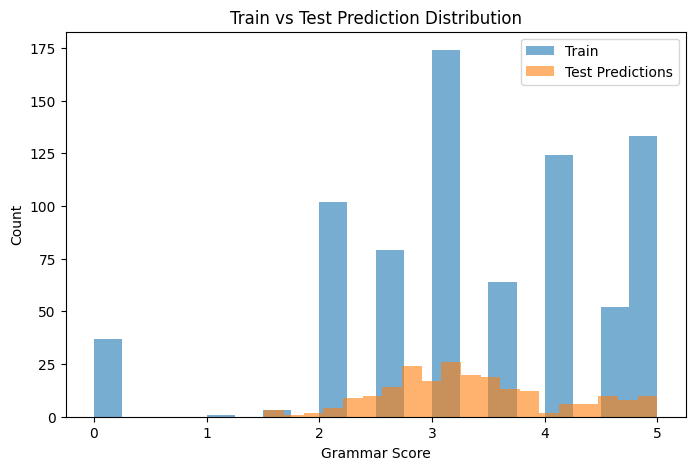

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    y,
    bins=20,
    alpha=0.6,
    label="Train"
)

plt.hist(
    blend_test,
    bins=20,
    alpha=0.6,
    label="Test Predictions"
)

plt.xlabel("Grammar Score")
plt.ylabel("Count")
plt.title("Train vs Test Prediction Distribution")
plt.legend()
plt.show()

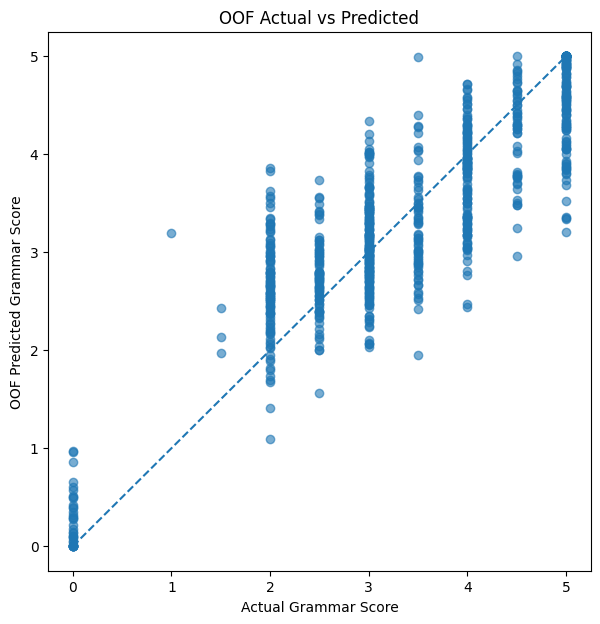

In [55]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y,
    blend_oof,
    alpha=0.6
)

plt.plot(
    [0, 5],
    [0, 5],
    linestyle="--"
)

plt.xlabel("Actual Grammar Score")
plt.ylabel("OOF Predicted Grammar Score")

plt.title(
    "OOF Actual vs Predicted"
)

plt.show()

In [56]:
submission = pd.DataFrame({
    FILENAME_COL: test_df[FILENAME_COL],
    TARGET_COL: blend_test
})

submission.head()

,filename,label
0,audio_128.wav,3.433040
1,audio_156.wav,4.512333
2,audio_19.wav,4.579827
3,audio_108.wav,2.187357
4,audio_206.wav,2.337372


In [57]:
SUBMISSION_PATH = "/kaggle/working/submission.csv"

submission.to_csv(
    SUBMISSION_PATH,
    index=False
)

print(
    "Saved:",
    SUBMISSION_PATH
)

print(
    submission.shape
)

display(
    submission.head(10)
)

Saved: /kaggle/working/submission.csv
(216, 2)


,filename,label
0,audio_128.wav,3.433040
1,audio_156.wav,4.512333
2,audio_19.wav,4.579827
3,audio_108.wav,2.187357
4,audio_206.wav,2.337372
5,audio_161.wav,3.235259
6,audio_215.wav,3.380862
7,audio_213.wav,1.571796
8,audio_11.wav,3.178036
9,audio_155.wav,3.861119


In [58]:
check = pd.read_csv(
    SUBMISSION_PATH
)

print("Rows:", len(check))
print("Columns:", check.columns.tolist())

print(
    "Min prediction:",
    check[TARGET_COL].min()
)

print(
    "Max prediction:",
    check[TARGET_COL].max()
)

print(
    "Missing predictions:",
    check[TARGET_COL].isna().sum()
)

Rows: 216
Columns: ['filename', 'label']
Min prediction: 1.5115634077970617
Max prediction: 5.0
Missing predictions: 0
